<div style="border-left:5px solid #26748e;padding:12px 18px;background:#eef6fa;color:#16394a"><h1>Sentiment Classification</h1><p>Arafat Rahman · TF-IDF, Naive Bayes and Logistic Regression</p></div>

Classify English review sentences as positive or negative, compare two fixed baselines and test custom text through a reusable prediction helper.

## Results at a glance

On 585 held-out sentences, Multinomial Naive Bayes achieved **80.34% accuracy** and Logistic Regression **82.22%**. Logistic Regression made 104 errors versus 115 for Naive Bayes. These are observed results for this split, not a general superiority claim. After cleaning and deduplication, 2,925 of 3,000 source rows remain.

## Context and methods

Datheon's Task 4 requests text cleaning, stopword removal, lemmatization, TF-IDF with at most 5,000 features, Multinomial Naive Bayes, Logistic Regression and a custom-input helper. Models share a stratified 80/20 holdout, seed 42. Vocabulary and IDF are fitted on training text only. No tuning uses the test set.

**Source substitution:** the [official CSV](https://raw.githubusercontent.com/datasets/sample-reviews/main/sentiment_reviews.csv) returned HTTP 404 on 25 October 2026. This notebook explicitly substitutes [UCI Sentiment Labelled Sentences](https://archive.ics.uci.edu/dataset/331/sentiment+labelled+sentences): 1,000 sentences each from Amazon, IMDb and Yelp, equally divided between positive and negative labels in each source. Attribution: Kotzias (2015), [DOI 10.24432/C57604](https://doi.org/10.24432/C57604), CC BY 4.0.

### Key assumptions

These are selected English sentences, not representative full reviews. Only binary polarity is supported. Cleaning preserves negation words but does not solve sarcasm or context. Exact normalized duplicates are removed before splitting; conflicting-label normalized groups are excluded and counted. Related sentences from the same original review cannot be grouped because review IDs are unavailable.

## 1. Libraries and reproducibility

In [1]:
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile
from io import BytesIO
from html import unescape
from importlib.metadata import version
from functools import lru_cache
import re, hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
from IPython.display import display, Markdown
SEED=42
LABELS=['Negative','Positive']
COLORS={'Multinomial Naive Bayes':'#26748e','Logistic Regression':'#c67d23'}
np.random.seed(SEED)
sns.set_theme(style='whitegrid',font_scale=1.05)
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':220,'axes.spines.top':False,'axes.spines.right':False,'grid.alpha':0.2})
cwd=Path.cwd()
if cwd.name=='Task_04_Sentiment_Classification': TASK=cwd
elif (cwd/'Task_04_Sentiment_Classification').is_dir(): TASK=cwd/'Task_04_Sentiment_Classification'
elif cwd==Path('/kaggle/working'):
    TASK=cwd/'Task_04_Sentiment_Classification'
    TASK.mkdir(exist_ok=True)
else: raise RuntimeError('Run from repository root, task folder or /kaggle/working.')
RESULTS,FIGURES=TASK/'results',TASK/'figures'
RESULTS.mkdir(exist_ok=True); FIGURES.mkdir(exist_ok=True)
def save(fig,name): fig.savefig(FIGURES/name,bbox_inches='tight',facecolor='white')
display(pd.Series({x:version(x) for x in ['numpy','pandas','scikit-learn','nltk','matplotlib','seaborn']},name='Version').to_frame())

,Version
numpy,2.5.4
pandas,3.0.6
scikit-learn,1.9.1
nltk,3.10.4
matplotlib,3.11.2
seaborn,0.13.2


## 2. Load and validate the source
Read each line using its final tab separator so quotation marks inside IMDb sentences cannot merge records. The raw dataset remains in memory.

In [2]:
DATA_URL='https://archive.ics.uci.edu/static/public/331/sentiment+labelled+sentences.zip'
with urlopen(DATA_URL,timeout=60) as response: source=response.read()
source_sha256=hashlib.sha256(source).hexdigest()
rows=[]
with ZipFile(BytesIO(source)) as archive:
    for domain,filename in [('Amazon','amazon_cells_labelled.txt'),('IMDb','imdb_labelled.txt'),('Yelp','yelp_labelled.txt')]:
        name=next(x for x in archive.namelist() if x.endswith('/'+filename) and not x.startswith('__MACOSX/'))
        for line_number,line in enumerate(archive.read(name).decode('utf-8').strip().split('\n'),1):
            text,label=line.rsplit('\t',1)
            rows.append({'source_id':f'{domain}:{line_number}','domain':domain,'text':text,'label':int(label)})
reviews=pd.DataFrame(rows)
assert reviews.shape==(3000,4) and reviews.source_id.is_unique
assert not reviews.isna().any().any() and reviews.text.str.strip().ne('').all()
assert set(reviews.label)=={0,1}
assert reviews.groupby(['domain','label']).size().eq(500).all()
print('Source SHA-256:',source_sha256)
print('Raw shape:',reviews.shape,'Exact repeated text/label rows:',reviews.duplicated(['text','label']).sum())
display(reviews.groupby(['domain','label']).size().unstack().rename(columns=dict(enumerate(LABELS))))
display(reviews.head(3))

Source SHA-256: afc26626d710899948693e1a61405dce197f57ffa719fa1130d346b4cc095343
Raw shape: (3000, 4) Exact repeated text/label rows: 17


label,Negative,Positive
domain,,
Amazon,500,500
IMDb,500,500
Yelp,500,500


,source_id,domain,text,label
0,Amazon:1,Amazon,So there is no way for me to plug it in here i...,0
1,Amazon:2,Amazon,"Good case, Excellent value.",1
2,Amazon:3,Amazon,Great for the jawbone.,1


## 3. Clean and tokenize
Decode HTML entities, remove HTML tags, lowercase, expand common negative contractions, tokenize alphabetic words, remove English stopwords except negations, then apply WordNet noun lemmatization. Fixed linguistic resources do not learn from test data. Noun-only lemmatization is deliberately simple and does not resolve every verb form.

In [3]:
for resource in ['stopwords','wordnet']:
    nltk.download(resource,quiet=True,raise_on_error=True)
STOPWORDS=set(stopwords.words('english'))-{'no','not','nor','never'}
lemmatizer=WordNetLemmatizer()
@lru_cache(maxsize=20000)
def clean_text(text):
    text=re.sub(r'<[^>]+>',' ',unescape(text)).lower().replace('’',"'")
    text=text.replace("won't",'will not').replace("can't",'can not')
    text=re.sub(r"n't\b",' not',text)
    tokens=re.findall(r'[a-z]+',text)
    return ' '.join(lemmatizer.lemmatize(t) for t in tokens if t not in STOPWORDS and (len(t)>1 or t=='i'))
assert 'not' in clean_text("<b>I didn't like it.</b>").split()
assert clean_text('cars')=='car'
reviews['clean_text']=reviews.text.map(clean_text)
empty_count=int(reviews.clean_text.eq('').sum())
nonempty=reviews.loc[reviews.clean_text.ne('')].copy()
conflicts=nonempty.groupby('clean_text').label.nunique()
conflict_keys=set(conflicts[conflicts>1].index)
conflict_rows=int(nonempty.clean_text.isin(conflict_keys).sum())
consistent=nonempty.loc[~nonempty.clean_text.isin(conflict_keys)].copy()
duplicate_count=int(consistent.duplicated('clean_text').sum())
data=consistent.drop_duplicates('clean_text',keep='first').reset_index(drop=True)
assert data.clean_text.is_unique and data.clean_text.ne('').all()
quality={'raw_rows':len(reviews),'empty_after_cleaning':empty_count,'conflicting_rows_removed':conflict_rows,'duplicate_rows_removed':duplicate_count,'retained_rows':len(data)}
assert sum([empty_count,conflict_rows,duplicate_count,len(data)])==len(reviews)
display(pd.Series(quality,name='Rows').to_frame())
display(data[['text','clean_text']].head(4))

,Rows
raw_rows,3000
empty_after_cleaning,2
conflicting_rows_removed,0
duplicate_rows_removed,73
retained_rows,2925


,text,clean_text
0,So there is no way for me to plug it in here i...,no way plug u unless go converter
1,"Good case, Excellent value.",good case excellent value
2,Great for the jawbone.,great jawbone
3,Tied to charger for conversations lasting more...,tied charger conversation lasting minute major...


## 4. Stratified train/test split
Deduplication uses a fixed cleaning rule; model fitting sees only the training partition. Stratification preserves sentiment balance. Domain proportions are reported, not assumed.

In [4]:
train,test=train_test_split(data,test_size=0.20,stratify=data.label,random_state=SEED)
assert set(train.source_id).isdisjoint(test.source_id)
assert set(train.clean_text).isdisjoint(test.clean_text)
y_train,y_test=train.label,test.label
split=pd.DataFrame({'Train':y_train.value_counts(),'Test':y_test.value_counts()}).sort_index()
split.index=LABELS
display(split)
display(pd.crosstab(pd.concat([train.assign(split='Train'),test.assign(split='Test')]).domain,pd.concat([train.assign(split='Train'),test.assign(split='Test')]).split))
print(f'Train: {len(train):,}; test: {len(test):,}; no normalized-text overlap.')

,Train,Test
Negative,1168,292
Positive,1172,293


split,Test,Train
domain,,
Amazon,180,787
IMDb,186,794
Yelp,219,759


Train: 2,340; test: 585; no normalized-text overlap.


## 5. Training text exploration

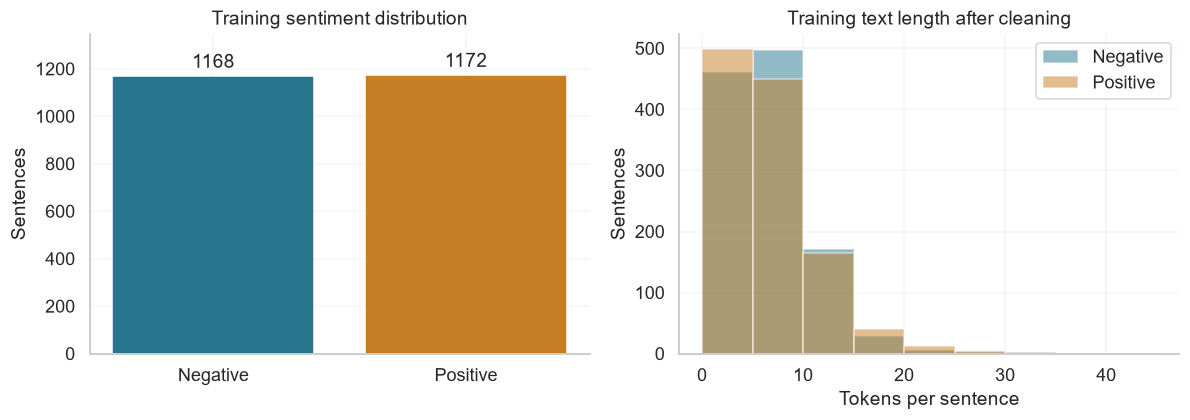

In [5]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
counts=y_train.value_counts().sort_index()
bars=axes[0].bar(LABELS,counts,color=['#26748e','#c67d23'])
axes[0].bar_label(bars,padding=3)
axes[0].set(title='Training sentiment distribution',ylabel='Sentences',ylim=(0,counts.max()*1.15))
bin_edges=np.arange(0,int(train.clean_text.str.split().str.len().max())+6,5)
for label,color in [(0,'#26748e'),(1,'#c67d23')]:
    lengths=train.loc[train.label.eq(label),'clean_text'].str.split().str.len()
    axes[1].hist(lengths,bins=bin_edges,alpha=0.5,color=color,label=LABELS[label],edgecolor='white')
axes[1].set(title='Training text length after cleaning',xlabel='Tokens per sentence',ylabel='Sentences')
axes[1].legend()
fig.tight_layout(); save(fig,'training_exploration.png'); plt.show()

## 6. TF-IDF pipelines and model training
Both pipelines use unigrams and bigrams, at most 5,000 features, and identical training rows. The vectorizer applies the same cleaner to training, held-out and custom text. Fixed baseline settings: Naive Bayes `alpha=1.0`; Logistic Regression `C=1.0`, `max_iter=1000`. No held-out tuning or model selection is performed.

In [6]:
def pipeline(estimator):
    return Pipeline([('tfidf',TfidfVectorizer(preprocessor=clean_text,lowercase=False,max_features=5000,ngram_range=(1,2))),('model',estimator)])
models={'Multinomial Naive Bayes':pipeline(MultinomialNB(alpha=1.0)),
        'Logistic Regression':pipeline(LogisticRegression(C=1.0,max_iter=1000,random_state=SEED))}
for name,model in models.items():
    model.fit(train.text,y_train)
    vectorizer=model.named_steps['tfidf']
    assert len(vectorizer.vocabulary_)<=5000
    print(name,':',len(vectorizer.vocabulary_),'TF-IDF features')
np.testing.assert_array_equal(models['Multinomial Naive Bayes'].named_steps['tfidf'].get_feature_names_out(),models['Logistic Regression'].named_steps['tfidf'].get_feature_names_out())
# A term appearing only in held-out text must not enter the learned vocabulary.
vectorizer=models['Multinomial Naive Bayes'].named_steps['tfidf']
analyze=vectorizer.build_analyzer()
training_terms={term for text in train.text for term in analyze(text)}
assert set(vectorizer.vocabulary_).issubset(training_terms)

Multinomial Naive Bayes : 5000 TF-IDF features
Logistic Regression : 5000 TF-IDF features


## 7. Held-out performance
Macro metrics weight both classes equally. Per-class scores and support appear in the next section. The majority baseline uses the majority label from training.

In [7]:
predictions={name:model.predict(test.text) for name,model in models.items()}
rows=[]
for name,pred in predictions.items():
    rows.append({'Model':name,'Accuracy':accuracy_score(y_test,pred),'Macro Precision':precision_score(y_test,pred,average='macro',zero_division=0),'Macro Recall':recall_score(y_test,pred,average='macro',zero_division=0),'Macro F1':f1_score(y_test,pred,average='macro',zero_division=0)})
comparison=pd.DataFrame(rows).set_index('Model')
comparison.to_csv(RESULTS/'model_comparison.csv')
display(comparison.round(4))
baseline=accuracy_score(y_test,np.full(len(test),y_train.mode()[0]))
print(f'Training-majority baseline test accuracy: {baseline:.2%}')
saved=test[['source_id','domain','label']].copy()
for name,pred in predictions.items(): saved[name]=pred
saved.to_csv(RESULTS/'test_predictions.csv',index=False)

,Accuracy,Macro Precision,Macro Recall,Macro F1
Model,,,,
Multinomial Naive Bayes,0.8034,0.8039,0.8034,0.8033
Logistic Regression,0.8222,0.8223,0.8222,0.8222


Training-majority baseline test accuracy: 50.09%


## 8. Classification reports and confusion matrices

Multinomial Naive Bayes
              precision    recall  f1-score   support

    Negative     0.8149    0.7842    0.7993       292
    Positive     0.7928    0.8225    0.8074       293

    accuracy                         0.8034       585
   macro avg     0.8039    0.8034    0.8033       585
weighted avg     0.8038    0.8034    0.8033       585

Logistic Regression
              precision    recall  f1-score   support

    Negative     0.8264    0.8151    0.8207       292
    Positive     0.8182    0.8294    0.8237       293

    accuracy                         0.8222       585
   macro avg     0.8223    0.8222    0.8222       585
weighted avg     0.8223    0.8222    0.8222       585



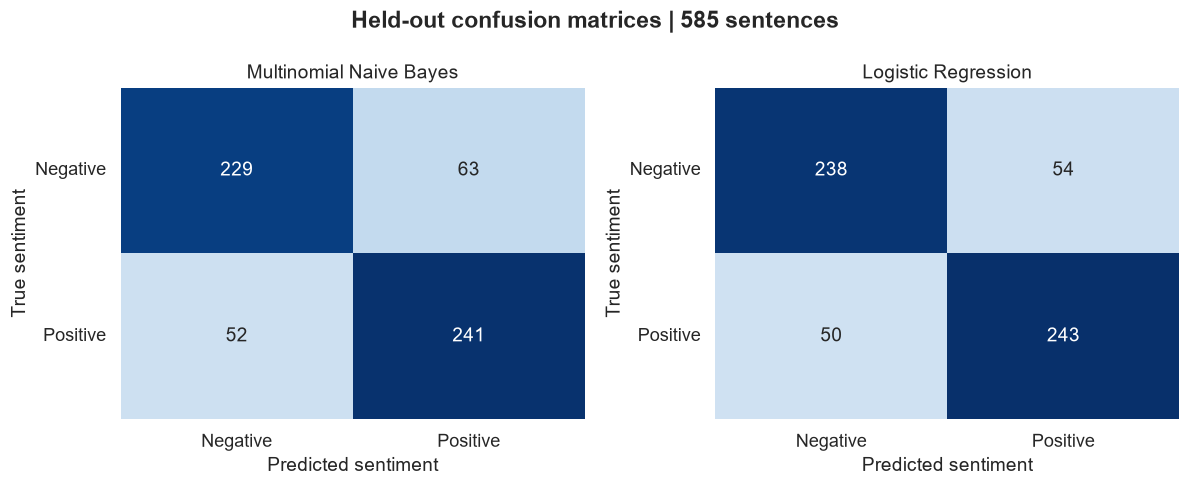

In [8]:
reports=[]; matrices={}
for name,pred in predictions.items():
    report=classification_report(y_test,pred,labels=[0,1],target_names=LABELS,digits=4,zero_division=0)
    reports.append(name+'\n'+report)
    print(name+'\n'+report)
    matrices[name]=confusion_matrix(y_test,pred,labels=[0,1])
(RESULTS/'classification_reports.txt').write_text('\n'.join(reports),encoding='utf-8')
fig,axes=plt.subplots(1,2,figsize=(11,4.5))
for ax,(name,matrix) in zip(axes,matrices.items()):
    sns.heatmap(matrix,annot=True,fmt='d',cmap='Blues',vmin=0,vmax=max(m.max() for m in matrices.values()),xticklabels=LABELS,yticklabels=LABELS,ax=ax,cbar=False)
    ax.set(title=name,xlabel='Predicted sentiment',ylabel='True sentiment'); ax.tick_params(axis='y',rotation=0)
fig.suptitle(f'Held-out confusion matrices | {len(test)} sentences',weight='bold')
fig.tight_layout(); save(fig,'confusion_matrices.png'); plt.show()

## 9. Model comparison

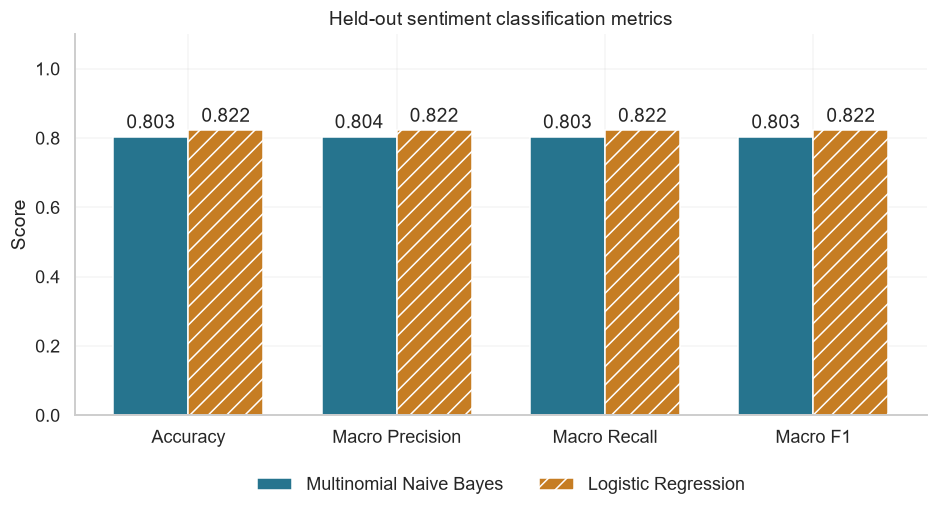

In [9]:
fig,ax=plt.subplots(figsize=(10,4.5))
x=np.arange(len(comparison.columns))
for i,(name,row) in enumerate(comparison.iterrows()):
    bars=ax.bar(x+(i-0.5)*0.36,row.values,width=0.36,label=name,color=COLORS[name],hatch='' if i==0 else '//')
    ax.bar_label(bars,labels=[f'{v:.3f}' for v in row],padding=3)
ax.set_xticks(x,comparison.columns)
ax.set(ylim=(0,1.1),ylabel='Score',title='Held-out sentiment classification metrics')
ax.legend(loc='upper center',bbox_to_anchor=(0.5,-0.12),ncol=2,frameon=False)
save(fig,'model_comparison.png'); plt.show()

## 10. Interpretable language signals
The most positive and negative Logistic Regression coefficients describe associations in this training vocabulary. They do not explain intent or establish causality; correlated terms and short sentences limit interpretation.

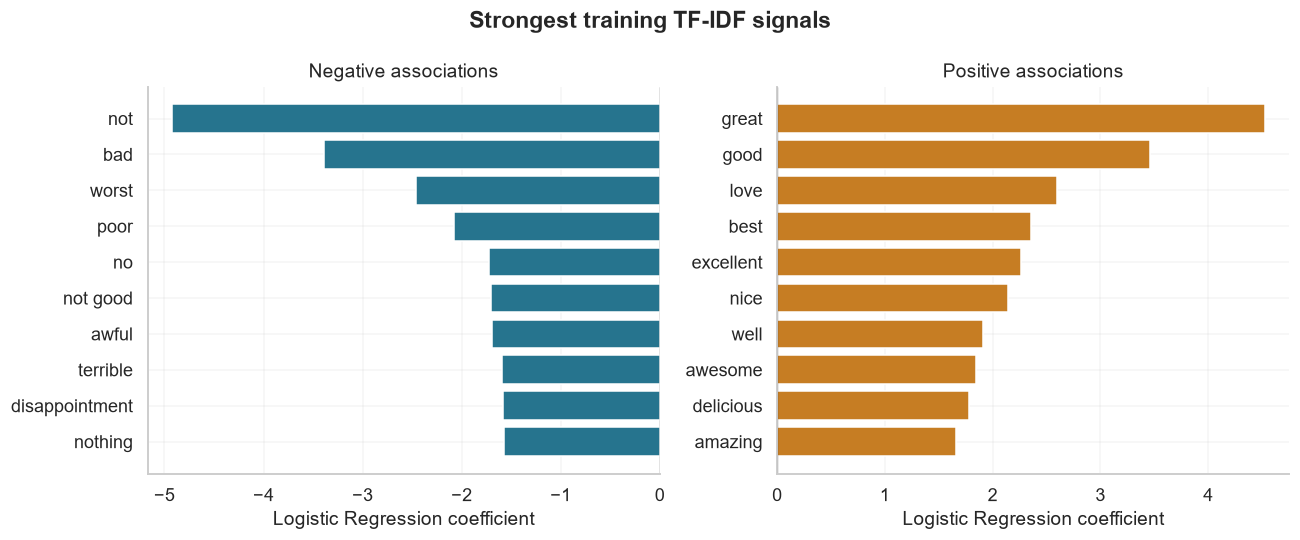

In [10]:
lr=models['Logistic Regression']
terms=lr.named_steps['tfidf'].get_feature_names_out()
weights=lr.named_steps['model'].coef_[0]
importance=pd.Series(weights,index=terms).sort_values()
pd.DataFrame({'term':terms,'coefficient':weights}).sort_values('coefficient').to_csv(RESULTS/'term_coefficients.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(12,5))
for ax,values,title,color in [(axes[0],importance.head(10).sort_values(ascending=False),'Negative associations','#26748e'),(axes[1],importance.tail(10),'Positive associations','#c67d23')]:
    ax.barh(values.index,values.values,color=color)
    ax.axvline(0,color='#444444',lw=0.8)
    ax.set(title=title,xlabel='Logistic Regression coefficient')
fig.suptitle('Strongest training TF-IDF signals',weight='bold')
fig.tight_layout(); save(fig,'sentiment_terms.png'); plt.show()

## 11. Error analysis
Export every error for both models by source ID. Inspect a small sample below; snippets are bounded to keep the notebook readable. Domain-level scores describe this split, not separate domain-generalization tests.

In [11]:
errors=[]; domain_rows=[]
for name,pred in predictions.items():
    mask=pred!=y_test.to_numpy()
    print(name,':',int(mask.sum()),'incorrect predictions')
    for (_,row),prediction in zip(test.loc[mask].iterrows(),pred[mask]):
        errors.append({'Model':name,'source_id':row.source_id,'domain':row.domain,'true_label':int(row.label),'predicted_label':int(prediction),'snippet':row.text[:180]})
    for domain in sorted(test.domain.unique()):
        selected=test.domain.eq(domain).to_numpy()
        domain_rows.append({'Model':name,'Domain':domain,'Support':int(selected.sum()),'Accuracy':accuracy_score(y_test.to_numpy()[selected],pred[selected])})
error_table=pd.DataFrame(errors)
error_table.to_csv(RESULTS/'misclassified_reviews.csv',index=False)
display(error_table.groupby('Model').head(3))
domains=pd.DataFrame(domain_rows)
domains.to_csv(RESULTS/'domain_performance.csv',index=False)
display(domains.round(4))

Multinomial Naive Bayes : 115 incorrect predictions
Logistic Regression : 104 incorrect predictions


,Model,source_id,domain,true_label,predicted_label,snippet
0,Multinomial Naive Bayes,IMDb:493,IMDb,1,0,But this movie really got to me.
1,Multinomial Naive Bayes,Amazon:46,Amazon,1,0,It has all the features I want
2,Multinomial Naive Bayes,Amazon:227,Amazon,1,0,I usually don't like headbands but this one is...
115,Logistic Regression,IMDb:493,IMDb,1,0,But this movie really got to me.
116,Logistic Regression,Amazon:46,Amazon,1,0,It has all the features I want
117,Logistic Regression,Amazon:227,Amazon,1,0,I usually don't like headbands but this one is...


,Model,Domain,Support,Accuracy
0,Multinomial Naive Bayes,Amazon,180,0.8000
1,Multinomial Naive Bayes,IMDb,186,0.8011
2,Multinomial Naive Bayes,Yelp,219,0.8082
3,Logistic Regression,Amazon,180,0.8111
4,Logistic Regression,IMDb,186,0.8333
5,Logistic Regression,Yelp,219,0.8219


## 12. Predict custom text
`predict_sentiment(text, model_name)` accepts live user text after running the notebook. Logistic Regression is the predefined default, not a test-selected winner. Empty or out-of-vocabulary input returns **Unknown**. Other inputs receive a binary prediction; scores are not calibrated confidence. These examples are demonstrations, not additional test metrics.

In [12]:
def predict_sentiment(text,model_name='Logistic Regression'):
    if not isinstance(text,str): raise TypeError('text must be a string')
    if model_name not in models: raise ValueError('Unknown model name')
    model=models[model_name]
    features=model.named_steps['tfidf'].transform([text])
    if features.nnz==0:
        return {'sentiment':'Unknown','positive_score':None,'reason':'No recognized vocabulary after cleaning','model':model_name}
    score=float(model.predict_proba([text])[0,1])
    label=int(model.predict([text])[0])
    return {'sentiment':LABELS[label],'positive_score':score,'model':model_name}
examples=['I love this product. It works beautifully!','The movie was boring and a waste of time.','The service was not good.','', 'zzzxxyyqq']
display(pd.DataFrame([{'text':text,**predict_sentiment(text)} for text in examples]))
assert predict_sentiment('')['sentiment']=='Unknown'
assert predict_sentiment('zzzxxyyqq')['sentiment']=='Unknown'
# Edit the sentence below and rerun this cell to test your own review.
predict_sentiment('The food was delicious and the staff were helpful.')

,text,sentiment,positive_score,model,reason
0,I love this product. It works beautifully!,Positive,0.852435,Logistic Regression,NaN
1,The movie was boring and a waste of time.,Negative,0.181872,Logistic Regression,NaN
2,The service was not good.,Negative,0.185928,Logistic Regression,NaN
3,,Unknown,NaN,Logistic Regression,No recognized vocabulary after cleaning
4,zzzxxyyqq,Unknown,NaN,Logistic Regression,No recognized vocabulary after cleaning


{'sentiment': 'Positive',
 'positive_score': 0.7919356901608718,
 'model': 'Logistic Regression'}

## 13. Findings and limitations

In [13]:
for name,row in comparison.iterrows():
    display(Markdown(f"**{name}:** accuracy **{row['Accuracy']:.2%}**, macro F1 **{row['Macro F1']:.4f}**; **{int((predictions[name]!=y_test.to_numpy()).sum())}** test errors."))
leader=comparison['Macro F1'].idxmax()
display(Markdown(f'Highest observed macro F1 on this split: **{leader}**. This is descriptive; neither hyperparameters nor the default custom-input model were selected using the test results.'))
summary={**quality,'train_rows':len(train),'test_rows':len(test),'source_sha256':source_sha256,'baseline_accuracy':float(baseline),'highest_observed_macro_f1':leader,'source_substitution':'Official Datheon CSV returned HTTP 404; UCI Sentiment Labelled Sentences used.'}
(RESULTS/'run_summary.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')

**Multinomial Naive Bayes:** accuracy **80.34%**, macro F1 **0.8033**; **115** test errors.

**Logistic Regression:** accuracy **82.22%**, macro F1 **0.8222**; **104** test errors.

Highest observed macro F1 on this split: **Logistic Regression**. This is descriptive; neither hyperparameters nor the default custom-input model were selected using the test results.

474

A single random holdout does not measure uncertainty across splits or performance on future products. The source deliberately excludes neutral sentences; neutral, mixed, sarcastic and non-English inputs are outside the evaluated scope. Short text and unseen vocabulary can cause errors. Stopword removal and noun-only lemmatization can lose context despite preserved negation. Deduplication removes exact normalized matches, but related reviews may remain. The fallback dataset is disclosed rather than presented as the unavailable official CSV.

## 14. Verification

In [14]:
for name,matrix in matrices.items():
    assert matrix.sum()==len(test)
    np.testing.assert_allclose(np.trace(matrix)/matrix.sum(),comparison.loc[name,'Accuracy'])
    precisions=np.divide(np.diag(matrix),matrix.sum(axis=0),out=np.zeros(2,dtype=float),where=matrix.sum(axis=0)!=0)
    recalls=np.divide(np.diag(matrix),matrix.sum(axis=1),out=np.zeros(2,dtype=float),where=matrix.sum(axis=1)!=0)
    f1s=np.divide(2*precisions*recalls,precisions+recalls,out=np.zeros(2,dtype=float),where=(precisions+recalls)!=0)
    np.testing.assert_allclose([precisions.mean(),recalls.mean(),f1s.mean()],comparison.loc[name,['Macro Precision','Macro Recall','Macro F1']].to_numpy(dtype=float))
    assert len(error_table.loc[error_table.Model.eq(name)])==int((predictions[name]!=y_test.to_numpy()).sum())
for filename in ['training_exploration.png','confusion_matrices.png','model_comparison.png','sentiment_terms.png']:
    assert (FIGURES/filename).stat().st_size>1000
for filename in ['model_comparison.csv','classification_reports.txt','test_predictions.csv','term_coefficients.csv','misclassified_reviews.csv','domain_performance.csv','run_summary.json']:
    assert (RESULTS/filename).stat().st_size>0
print('Verified source, disjoint split, training-only vocabulary, metrics, helper and all output files.')

Verified source, disjoint split, training-only vocabulary, metrics, helper and all output files.
